# Ranking Spike Sequences by Fitness and Evaluating Cumulative Tip Scores

In this notebook, we explore multiple ranking methods to prioritize spike sequences based on their fitness estimates. These methods include:

- PyR0 fitness scores  
- EVEscape model scores  
- CoVFit model scores

We then evaluate the performance of each ranking by analyzing how well the top-ranked sequences capture future tips cumulatively over various time slices.

This approach helps identify ranking strategies that best forecast viral evolutionary trends and guide variant surveillance.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH +"final_df.parquet"
final_df = pd.read_parquet(DATA_PATH)
id_to_seq = load_data(ROOT_PATH + "sequence_dict.parquet")

refSeq = getReference(ROOT_PATH + 'ref_spike_genome.fa')

ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

eve_df = pd.read_csv(ROOT_PATH + 'EVEscape/EVEscore_Wuhan_A')

Create Disjoint time interval slices

In [32]:
# --- Define cutoff date ---
cutoff_date = "2023-06-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
#disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
print(f"Total future slices stored: {len(future_slices)}")

Total future slices stored: 2


In [33]:
# --- Compute tip counts for current circulating sequences ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = 5
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

# --- Compute tip counts for each future window ---
future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}



# --- Summary output ---
print(f"Computed current sequence DataFrame with {len(current_seq_df)} unique sequences")
print(f"Computed future sequence DataFrames for {len(future_seq_dfs)} windows")

Computed current sequence DataFrame with 1440 unique sequences
Computed future sequence DataFrames for 2 windows


# CoVFit Fitness Score Ranking

We will compute the CoVFit ranking using the precomputed per-sequence average fitness scores.

In [34]:
import subprocess
from pathlib import Path

# --- Write current sequences to FASTA for CoVFit ---
# Resolve CoVFit_CLI relative to this notebook (scripts/rank_analysis.ipynb)
_notebook_dir = Path.cwd()
if not (_notebook_dir / "rank_analysis.ipynb").exists():
    _notebook_dir = _notebook_dir / "scripts"
COVFIT_DIR = (_notebook_dir / ".." / "CoVFit_CLI").resolve()
fasta_path = Path(ROOT_PATH) / "current_seq_df.fasta"

missing_ids = []
n_written = 0
with open(fasta_path, "w") as fasta_file:
    for seq_id in current_seq_df["Sequence_ID"]:
        seq = id_to_seq.get(seq_id)
        if seq is None:
            missing_ids.append(seq_id)
            continue
        fasta_file.write(f">{seq_id}\n{seq}\n")
        n_written += 1

print(f"Wrote {n_written:,} sequences to {fasta_path}")
if missing_ids:
    print(f"Warning: {len(missing_ids):,} Sequence_IDs missing from id_to_seq")

# --- Run CoVFit CLI ---
covfit_outdir = ROOT_PATH.rstrip("/")
covfit_cmd = [
    "./covfit_cli",
    "-i",
    str(fasta_path),
    "-o",
    covfit_outdir,
    "-g",
    "-b",
    "16",
    "-f",
    "3",
#    "-d",
]
print("Running:", " ".join(covfit_cmd))

result = subprocess.run(
    covfit_cmd,
    cwd=str(COVFIT_DIR),
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError(f"covfit_cli failed with exit code {result.returncode}")

covfit_output = f"{covfit_outdir}/CoVFit_Predictions_fold_3.tsv"
print(f"CoVFit predictions written to {covfit_output}")

Wrote 1,440 sequences to /data/pgangwar/vaccinescout/data/current_seq_df.fasta
Running: ./covfit_cli -i /data/pgangwar/vaccinescout/data/current_seq_df.fasta -o /data/pgangwar/vaccinescout/data -g -b 16 -f 3
Initializing model. Please wait...
Tokenizing sequences for model input
Running CoVFit
Predictions completed
Writing output to /data/pgangwar/vaccinescout/data/CoVFit_Predictions_fold_3.tsv
Done

Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.

100%|██████████| 45/45 [01:57<00:00,  2.61s/it]

CoVFit predictions written to /data/pgangwar/vaccinescout/data/CoVFit_Predictions_fold_3.tsv


In [35]:
# --- Load CoVFit fitness scores ---
import subprocess
from pathlib import Path
_notebook_dir = Path.cwd()
COVFIT_DIR = (_notebook_dir / ".." / "CoVFit_CLI").resolve()
covfit_outdir = ROOT_PATH.rstrip("/")
covfit_output = f"{covfit_outdir}/CoVFit_Predictions_fold_3.tsv"



covfit_score_df = pd.read_csv(covfit_output, sep="\t")

# --- Standardize column names ---
covfit_score_df = covfit_score_df.rename(columns={"seq_name": "Sequence_ID"})

# --- Merge fitness scores with current sequence DataFrame ---
current_seq_df = current_seq_df.merge(
    covfit_score_df[["Sequence_ID", "fitness_mean"]],
    on="Sequence_ID",
    how="left"
)

# --- Summary output ---
print(f"Loaded {len(covfit_score_df)} CoVFit score entries")
print(f"Merged fitness scores into current sequence DataFrame with {len(current_seq_df)} sequences")

Loaded 1440 CoVFit score entries
Merged fitness scores into current sequence DataFrame with 1440 sequences


# PyR0 and EVEscape Ranking

Rank sequences using:
- **PyR₀ score**: product of R/Rₐ values across all spike mutations.  
- **EVEscape score**: sum of EVEsape scores across all soike mutations using Wuhan_A scoring.  


In [36]:
# --- Build mutation-to-score dictionaries ---
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

mutation_score_dict_eve = (
    eve_df.set_index("mutations")["EVEscape"].to_dict()
)

# --- Summary output ---
print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")
print(f"Loaded {len(mutation_score_dict_eve)} EVEscape mutation scores")

Loaded 2478 PyR₀ mutation scores
Loaded 24187 EVEscape mutation scores


In [37]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

# --- Compute EVEscape fitness scores ---
current_seq_df = add_fitness_scores_eve(current_seq_df, mutation_score_dict_eve)

# --- Summary output ---
print(f"Computed mutations and fitness scores for {len(current_seq_df)} sequences")

Computed mutations and fitness scores for 1440 sequences


In [38]:
# --- Build oracle ranking of current sequences for each future window ---
oracle_rankings = build_oracle_current_rankings(
    current_seq_df,
    future_seq_dfs,
    random_state=0,
)

print(f"Built oracle rankings for {len(oracle_rankings)} time windows")


Built oracle rankings for 2 time windows


In [39]:
# --- Compute cumulative tip percentages for all ranking methods ---
rank_results = compute_cumulative_tip_percentages_fast(
    current_seq_df,
    future_seq_dfs,
    oracle_rankings=oracle_rankings,
    max_rank=None
)

# --- Summary output ---
print(f"Computed cumulative tip percentages for {len(rank_results)} future time windows")


Computed cumulative tip percentages for 2 future time windows


In [40]:
# --- Compute normalized AUC ceiling per slice based on achievable tips ---
auc_ceil_dict = compute_auc_ceil_fraction(current_seq_df, future_seq_dfs)

# --- Display per-slice AUC ceilings ---
for time_slice, auc_ceil in auc_ceil_dict.items():
    print(f"Time slice: {time_slice} | Normalized AUC ceiling: {auc_ceil:.3f}")

Time slice: 6M_1 | Normalized AUC ceiling: 0.552
Time slice: 6M_2 | Normalized AUC ceiling: 0.048


In [41]:
# --- Compute normalized AUC for each ranking method ---
auc_scores = compute_auc_for_rank_results(rank_results)

# Plotting Results in a six-month period

The following plots visualize the performance of different ranking methods in capturing future tips.  
Each main panel shows the cumulative fraction of future tips captured by the top-ranked sequences over a given time interval.  
Inset panels display the corresponding normalized AUC scores for each method, with a reference line indicating the achievable ceiling.

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

sns.set_style("whitegrid")
sns.set_context("talk")

def plot_1x2_cumulative_auto(rank_results, auc_scores, auc_ceil, cutoff_date):
    slice_keys = list(rank_results.keys())[:4]

    legend_map = {
        "pyro": "PyR0 Fitness Score",
        "eve": "EVEscape Fitness Score",
        "covfit": "CoVFit Fitness Score",
        "tip_count": "Prevalence Score",
        "oracle": "Theoretical Best Ranking",
    }
    panel_head = {
        '6M_1' : '0 - 6 months',
        '6M_2' : '6 - 12 months'
    }

    base_palette = sns.color_palette("colorblind", n_colors=4)
    color_map = {
        "pyro": base_palette[0],
        "eve": base_palette[1],
        "covfit": base_palette[2],
        "tip_count": base_palette[3],
        "oracle": "black",
    }

    fig, axes = plt.subplots(1, 2, figsize=(24, 12), sharex=True, sharey=True)
    axes = axes.flatten()
    fig.suptitle(f'% Future Sequences Captured by Ranking Models: {cutoff_date}', fontsize=24, y = 0.95)

    legend_handles = []
    legend_labels = []

    for i, key in enumerate(slice_keys):
        df = rank_results[key]
        ax = axes[i]

        tip_cols = [col for col in df.columns if col.startswith('%_tips_')]
        methods = [col.replace('%_tips_', '') for col in tip_cols]
        bar_methods = [m for m in methods if m != "oracle"]

        # Main lineplots
        for method in methods:
            label_name = legend_map.get(method, method)
            line_kwargs = {
                "data": df,
                "x": "Rank",
                "y": f"%_tips_{method}",
                "ax": ax,
                "linewidth": 2.5,
                "color": color_map[method],
                "legend": False,
            }
            if method == "oracle":
                line_kwargs["linestyle"] = "--"
            sns.lineplot(**line_kwargs)
            if label_name not in legend_labels:
                legend_handles.append(ax.lines[-1])
                legend_labels.append(label_name)

        # X-axis ticks
        max_rank = int(df['Rank'].max())
        tick_base = 10 if max_rank <= 200 else 100 if max_rank <= 2000 else 1000
        tick_vals = list(range(tick_base, max_rank + 1, tick_base))
        if 10 not in tick_vals:
            tick_vals.insert(0, 10)
        if 500 not in tick_vals and 500 <= max_rank:
            tick_vals.append(500)
        tick_vals = sorted(set(tick_vals))
        tick_labels = [f'{x//1000}K' if x >= 1000 else str(x) for x in tick_vals]
        ax.set_xticks(tick_vals)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=16)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_title(f'% Future Tips Captured in {panel_head[key]} interval', fontsize=20)
        ax.set_xlabel('Top Rank', fontsize=18)
        ax.set_ylabel('% Normalized Tip Score', fontsize=18)

        # --- Inset AUC bar plot, bottom-right, no x-ticks ---
        if auc_scores is not None and key in auc_scores:
            inset_ax = inset_axes(ax, width="25%", height="25%", loc='lower right', borderpad=1)
            auc_values = [auc_scores[key].get(m, 0) for m in bar_methods]
            inset_ax.bar(range(len(bar_methods)), auc_values, color=[color_map[m] for m in bar_methods])
            inset_ax.set_title("AUC", fontsize=18)
            inset_ax.set_xticks([])  # remove x-ticks
            inset_ax.set_xlabel("")
            inset_ax.tick_params(axis='y', labelsize=14)
            inset_ax.set_ylim(0, 1)  # y-axis range fixed

            # --- Modification 1: remove grid lines ---
            inset_ax.grid(False)

            # --- Modification 2: add black line at ceiling value ---
            ceil_value = auc_ceil.get(key, 1.0)  # make sure auc_ceil_dict is available
            inset_ax.axhline(y=ceil_value, color='black', linestyle='--', linewidth=2)

    # Shared legend outside
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='center left',
        bbox_to_anchor=(0.9, 0.5),
        fontsize=16,
        title="Ranking Methods",
        title_fontsize=18
    )

    plt.show()

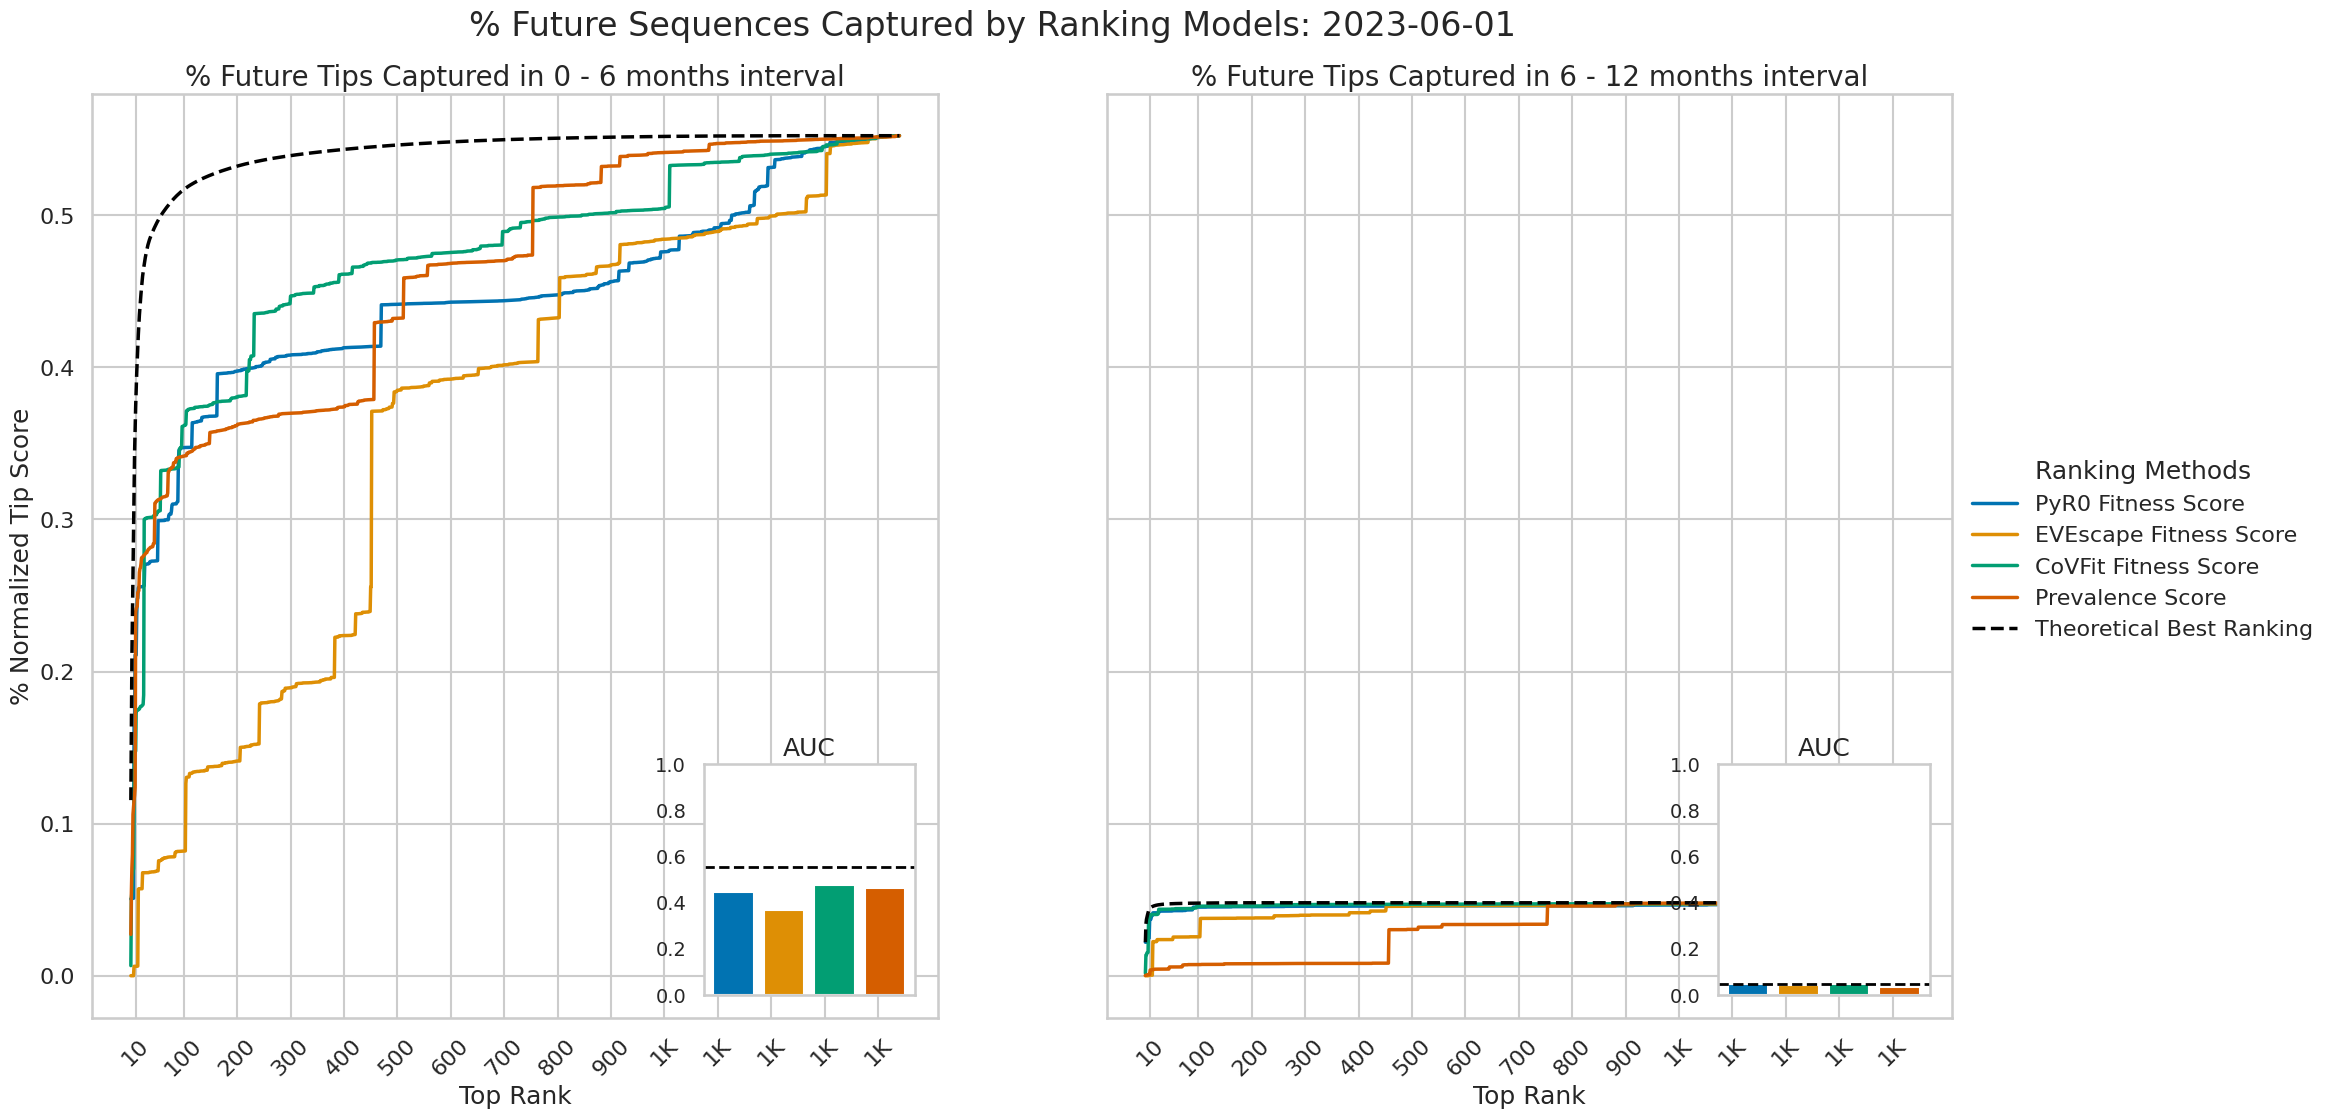

In [43]:
plot_1x2_cumulative_auto(rank_results=rank_results,
                         auc_scores=auc_scores,
                         auc_ceil=auc_ceil_dict,
                         cutoff_date=cutoff_date)

# Plotting Results Quarter Wise

The following plots visualize the performance of different ranking methods in capturing future tips.  
Each main panel shows the cumulative fraction of future tips captured by the top-ranked sequences over a given time interval.  
Inset panels display the corresponding normalized AUC scores for each method, with a reference line indicating the achievable ceiling.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np

sns.set_style("whitegrid")
sns.set_context("talk")

def plot_2x2_cumulative_auto(rank_results, auc_scores, auc_ceil, cutoff_date):
    slice_keys = list(rank_results.keys())[:4]

    legend_map = {
        "pyro": "PyR0 Fitness Score",
        "eve": "EVEscape Fitness Score",
        "covfit": "CoVFit Fitness Score",
        "tip_count": "Prevalence Score",
        "oracle": "Theoretical Best Ranking",
    }
    panel_head = {
        '3M_1' : '0 - 3 months',
        '3M_2' : '3 - 6 months',
        '3M_3' : '6 - 9 months',
        '3M_4' : '9 - 12 months'
    }

    base_palette = sns.color_palette("colorblind", n_colors=4)
    color_map = {
        "pyro": base_palette[0],
        "eve": base_palette[1],
        "covfit": base_palette[2],
        "tip_count": base_palette[3],
        "oracle": "black",
    }

    fig, axes = plt.subplots(2, 2, figsize=(24, 18), sharex=True, sharey=True)
    axes = axes.flatten()
    fig.suptitle(f'% Future Sequences Captured by Ranking Models: {cutoff_date}', fontsize=24, y = 0.95)

    legend_handles = []
    legend_labels = []

    for i, key in enumerate(slice_keys):
        df = rank_results[key]
        ax = axes[i]

        tip_cols = [col for col in df.columns if col.startswith('%_tips_')]
        methods = [col.replace('%_tips_', '') for col in tip_cols]
        bar_methods = [m for m in methods if m != "oracle"]

        # Main lineplots
        for method in methods:
            label_name = legend_map.get(method, method)
            line_kwargs = {
                "data": df,
                "x": "Rank",
                "y": f"%_tips_{method}",
                "ax": ax,
                "linewidth": 2.5,
                "color": color_map[method],
                "legend": False,
            }
            if method == "oracle":
                line_kwargs["linestyle"] = "--"
            sns.lineplot(**line_kwargs)
            if label_name not in legend_labels:
                legend_handles.append(ax.lines[-1])
                legend_labels.append(label_name)

        # X-axis ticks
        max_rank = int(df['Rank'].max())
        tick_base = 10 if max_rank <= 200 else 100 if max_rank <= 2000 else 1000
        tick_vals = list(range(tick_base, max_rank + 1, tick_base))
        if 10 not in tick_vals:
            tick_vals.insert(0, 10)
        if 500 not in tick_vals and 500 <= max_rank:
            tick_vals.append(500)
        tick_vals = sorted(set(tick_vals))
        tick_labels = [f'{x//1000}K' if x >= 1000 else str(x) for x in tick_vals]
        ax.set_xticks(tick_vals)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=16)
        ax.tick_params(axis='y', labelsize=16)

        ax.set_title(f'% Future Tips Captured in {panel_head[key]} interval', fontsize=20)
        ax.set_xlabel('Top Rank', fontsize=18)
        ax.set_ylabel('% Normalized Tip Score', fontsize=18)

        # --- Inset AUC bar plot, bottom-right, no x-ticks ---
        if auc_scores is not None and key in auc_scores:
            inset_ax = inset_axes(ax, width="25%", height="25%", loc='lower right', borderpad=1)
            auc_values = [auc_scores[key].get(m, 0) for m in bar_methods]
            inset_ax.bar(range(len(bar_methods)), auc_values, color=[color_map[m] for m in bar_methods])
            inset_ax.set_title("AUC", fontsize=18)
            inset_ax.set_xticks([])  # remove x-ticks
            inset_ax.set_xlabel("")
            inset_ax.tick_params(axis='y', labelsize=14)
            inset_ax.set_ylim(0, 1)  # y-axis range fixed

            # --- Modification 1: remove grid lines ---
            inset_ax.grid(False)

            # --- Modification 2: add black line at ceiling value ---
            ceil_value = auc_ceil.get(key, 1.0)  # make sure auc_ceil_dict is available
            inset_ax.axhline(y=ceil_value, color='black', linestyle='--', linewidth=2)

    # Shared legend outside
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc='center left',
        bbox_to_anchor=(0.9, 0.5),
        fontsize=16,
        title="Ranking Methods",
        title_fontsize=18
    )

    # plt.tight_layout(rect=[0, 0, 0.85, 0.95])
    #plt.savefig(f"/home/pgangwar@AD.UCSD.EDU/FutureCoV/{cutoff_date}/compartive_rank_trend.svg", format="svg")
    plt.show()

KeyError: '6M_1'

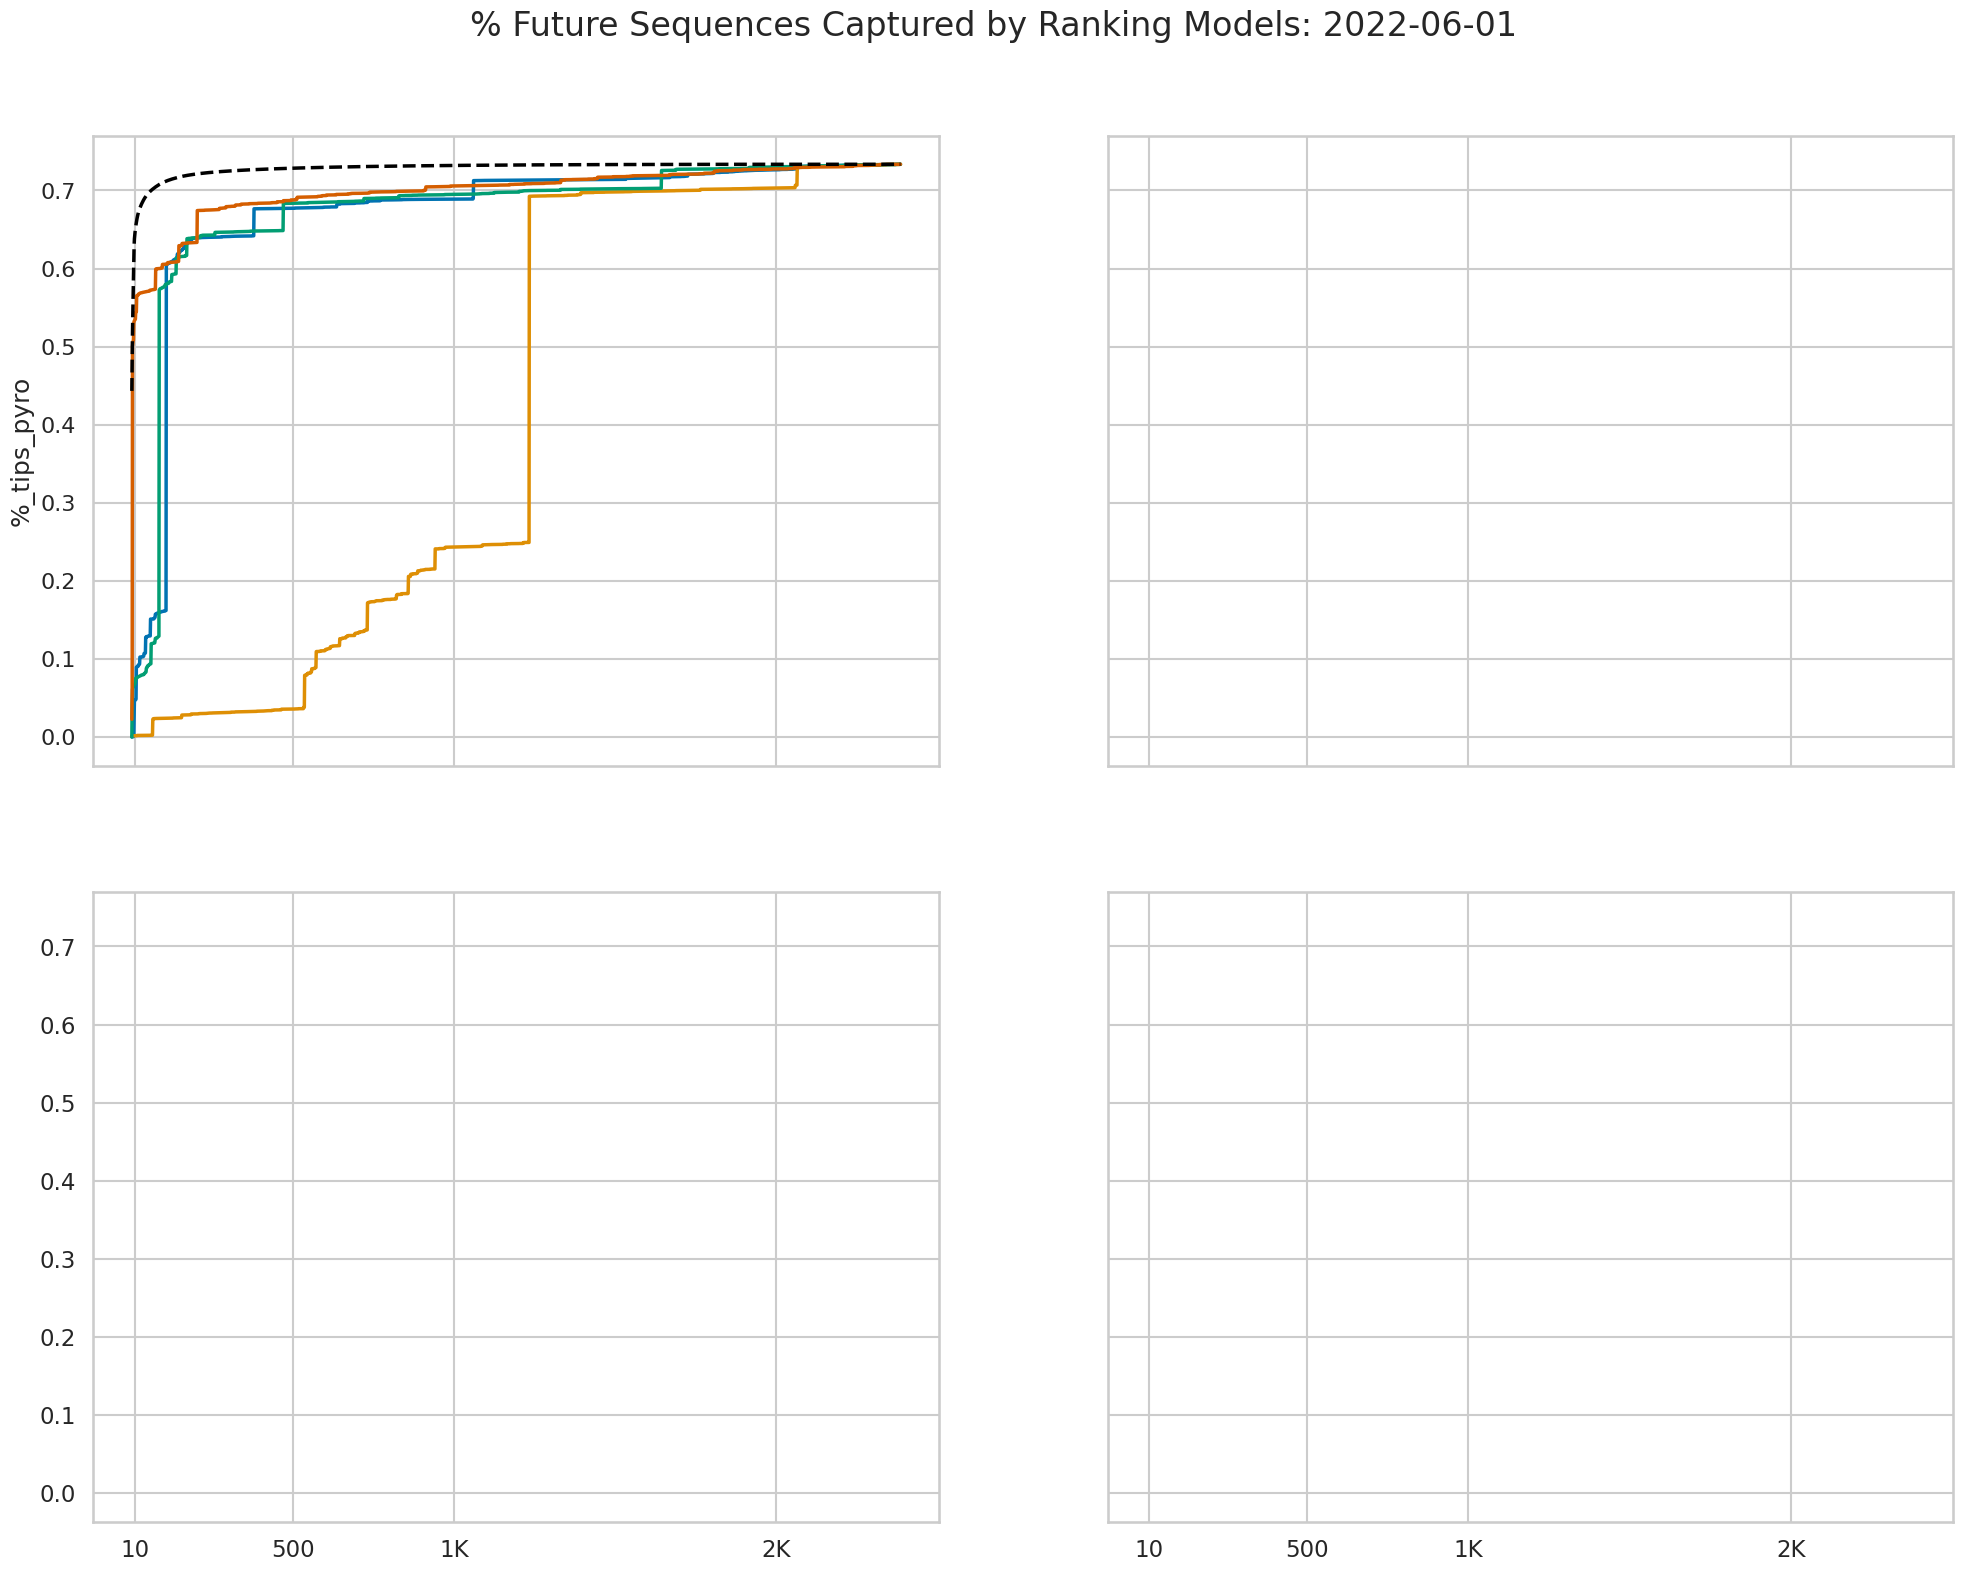

In [15]:
plot_2x2_cumulative_auto(rank_results=rank_results,
                         auc_scores=auc_scores,
                         auc_ceil=auc_ceil_dict,
                         cutoff_date=cutoff_date)